# Project 08 — Vehicle Rental Management System

## Project Overview

The Vehicle Rental Management System is a menu-driven Python application designed to manage vehicle rentals efficiently. It allows users to add vehicles, rent available vehicles, process vehicle returns, calculate rental charges, and maintain rental records.

## Objectives

- Add and manage vehicle details.
- Display available and rented vehicles.
- Rent available vehicles to customers.
- Return rented vehicles and update their availability.
- Calculate rental charges based on the number of rental days.
- Save and retrieve vehicle and rental records using JSON file handling.
- Maintain records even after restarting the program.

## Programming Concepts

- Object-Oriented Programming (OOP)
- Classes and Objects
- Constructors and Instance Methods
- Encapsulation
- Inheritance
- Abstraction
- File Handling
- JSON Data Storage
- Exception Handling
- Conditional Statements and Loops

## Technology Used

- Python
- Jupyter Notebook
- JSON for data storage

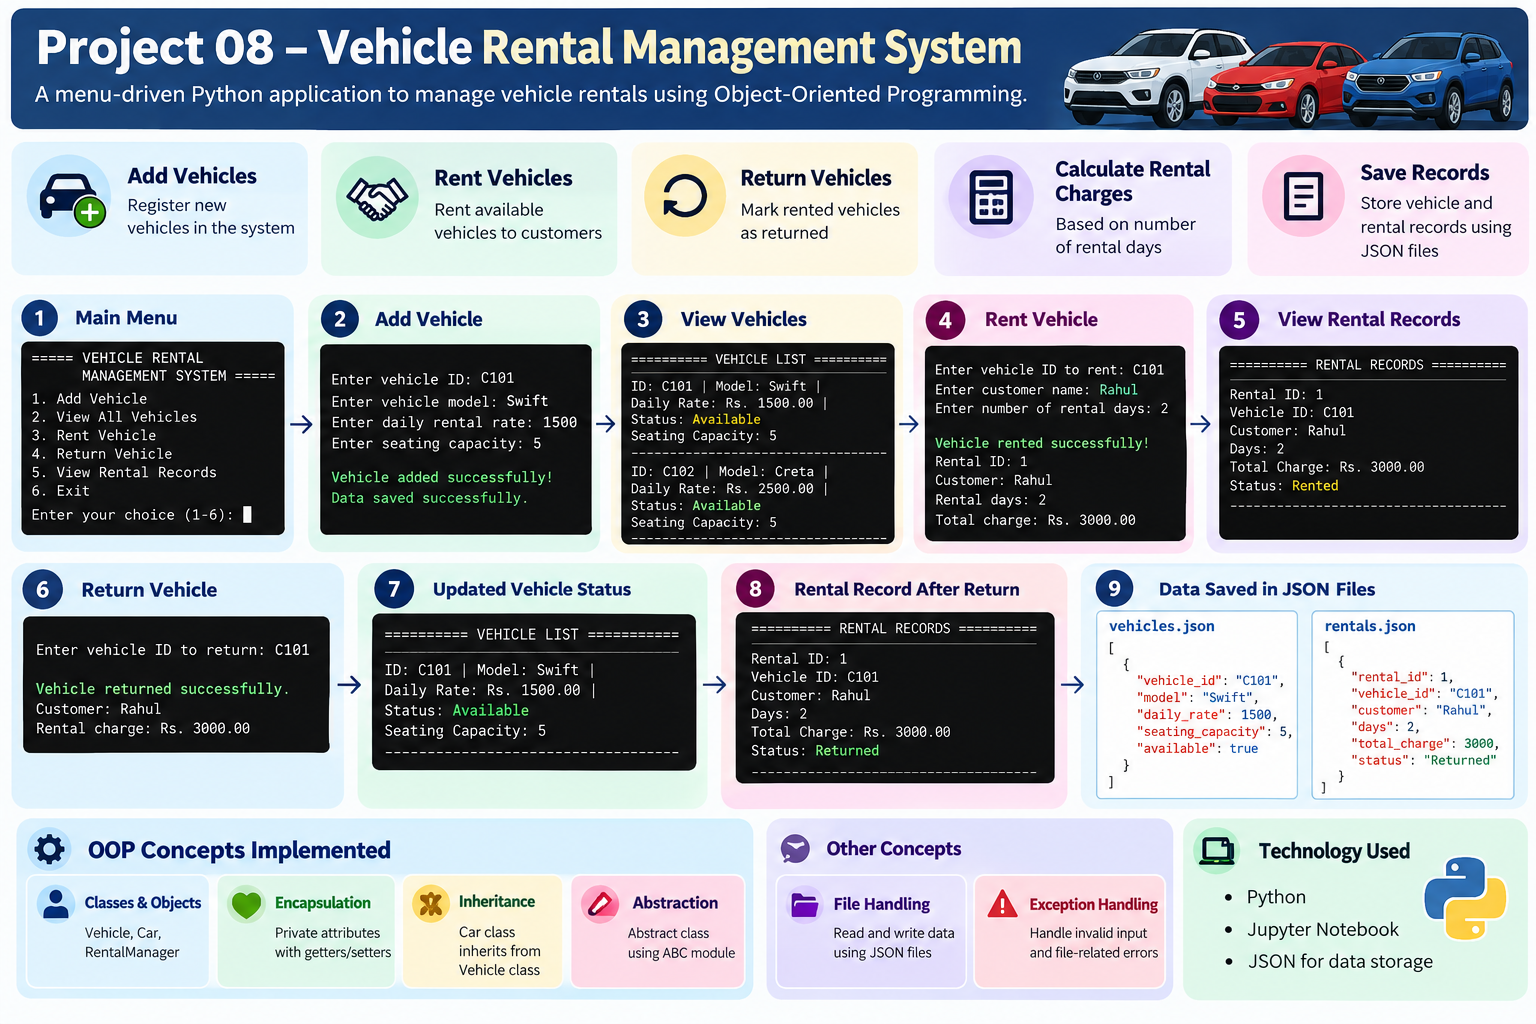

In [1]:

import json
import os
from abc import ABC, abstractmethod


In [2]:

import json
import os
from abc import ABC, abstractmethod


# ==========================================
# CLASS 1: ABSTRACT BASE CLASS
# ==========================================

class Rental(ABC):

    @abstractmethod
    def calculate_rent(self, days):
        pass


# ==========================================
# CLASS 2: VEHICLE CLASS
# ==========================================

class Vehicle(Rental):

    def __init__(self, vehicle_id, model, daily_rate, available=True):
        self.__vehicle_id = vehicle_id
        self.__model = model
        self.__daily_rate = daily_rate
        self.__available = available

    # Getter methods

    def get_vehicle_id(self):
        return self.__vehicle_id

    def get_model(self):
        return self.__model

    def get_daily_rate(self):
        return self.__daily_rate

    def get_availability(self):
        return self.__available

    # Setter methods

    def set_model(self, model):
        if model.strip() == "":
            raise ValueError("Model name cannot be empty.")
        self.__model = model

    def set_daily_rate(self, rate):
        if rate <= 0:
            raise ValueError("Daily rate must be greater than zero.")
        self.__daily_rate = rate

    def set_availability(self, available):
        self.__available = available

    # Rental charge calculation

    def calculate_rent(self, days):
        if days <= 0:
            raise ValueError("Rental days must be greater than zero.")
        return self.__daily_rate * days

    # Display vehicle information

    def display_vehicle(self):
        if self.__available:
            status = "Available"
        else:
            status = "Rented"

        print(
            f"ID: {self.__vehicle_id} | "
            f"Model: {self.__model} | "
            f"Daily Rate: Rs. {self.__daily_rate:.2f} | "
            f"Status: {status}"
        )

    # Convert vehicle object into dictionary for JSON

    def to_dict(self):
        return {
            "vehicle_id": self.__vehicle_id,
            "model": self.__model,
            "daily_rate": self.__daily_rate,
            "available": self.__available
        }


# ==========================================
# CLASS 3: CAR CLASS (INHERITANCE)
# ==========================================

class Car(Vehicle):

    def __init__(
        self, vehicle_id, model, daily_rate,
        seating_capacity, available=True
    ):
        super().__init__(
            vehicle_id, model, daily_rate, available
        )
        self.__seating_capacity = seating_capacity

    def get_seating_capacity(self):
        return self.__seating_capacity

    def display_vehicle(self):
        super().display_vehicle()
        print(f"Seating Capacity: {self.__seating_capacity}")


# ==========================================
# CLASS 4: RENTAL MANAGER
# ==========================================

class RentalManager:

    def __init__(self):
        self.__vehicles = []
        self.__rental_records = []

        self.__vehicle_file = "vehicles.json"
        self.__rental_file = "rentals.json"

        self.load_data()

    # Save vehicle and rental records

    def save_data(self):
        try:
            vehicle_data = [
                vehicle.to_dict()
                for vehicle in self.__vehicles
            ]

            with open(self.__vehicle_file, "w") as file:
                json.dump(vehicle_data, file, indent=4)

            with open(self.__rental_file, "w") as file:
                json.dump(
                    self.__rental_records, file, indent=4
                )

            print("Data saved successfully.")

        except (OSError, TypeError, ValueError) as error:
            print("Error saving data:", error)

    # Load previously saved data

    def load_data(self):
        try:
            with open(self.__vehicle_file, "r") as file:
                vehicle_data = json.load(file)

            for item in vehicle_data:
                car = Car(
                    item["vehicle_id"],
                    item["model"],
                    item["daily_rate"],
                    item.get("seating_capacity", 5),
                    item["available"]
                )
                self.__vehicles.append(car)

        except FileNotFoundError:
            print("Vehicle file not found. Starting fresh.")

        except (json.JSONDecodeError, OSError, KeyError, TypeError, ValueError) as error:
            print("Could not load vehicle data:", error)

        try:
            with open(self.__rental_file, "r") as file:
                self.__rental_records = json.load(file)

        except FileNotFoundError:
            print("Rental file not found. Starting fresh.")

        except (json.JSONDecodeError, OSError, TypeError) as error:
            print("Could not load rental records:", error)

    # Find a vehicle using its ID

    def find_vehicle(self, vehicle_id):
        for vehicle in self.__vehicles:
            if vehicle.get_vehicle_id() == vehicle_id:
                return vehicle

        return None

    # Add a new vehicle

    def add_vehicle(self):
        try:
            vehicle_id = input("Enter vehicle ID: ").strip()

            if vehicle_id == "":
                print("Vehicle ID cannot be empty.")
                return

            if self.find_vehicle(vehicle_id) is not None:
                print("This vehicle ID already exists.")
                return

            model = input("Enter vehicle model: ").strip()

            if model == "":
                print("Model cannot be empty.")
                return

            daily_rate = float(input("Enter daily rental rate: "))
            seating_capacity = int(
                input("Enter seating capacity: ")
            )

            if daily_rate <= 0 or seating_capacity <= 0:
                print("Rate and seating capacity must be positive.")
                return

            car = Car(
                vehicle_id, model, daily_rate, seating_capacity
            )

            self.__vehicles.append(car)
            self.save_data()

            print("Vehicle added successfully.")

        except ValueError:
            print("Invalid input. Enter a valid rate and capacity.")

    # Display all vehicles

    def view_vehicles(self):
        if len(self.__vehicles) == 0:
            print("No vehicles have been added yet.")
            return

        print("\n========== VEHICLE LIST ==========")

        for vehicle in self.__vehicles:
            vehicle.display_vehicle()
            print("-" * 35)

    # Rent a vehicle

    def rent_vehicle(self):
        vehicle_id = input("Enter vehicle ID to rent: ").strip()

        vehicle = self.find_vehicle(vehicle_id)

        if vehicle is None:
            print("Vehicle not found.")
            return

        if not vehicle.get_availability():
            print("Sorry, this vehicle is already rented.")
            return

        customer = input("Enter customer name: ").strip()

        if customer == "":
            print("Customer name cannot be empty.")
            return

        try:
            days = int(input("Enter number of rental days: "))

            if days <= 0:
                print("Rental days must be greater than zero.")
                return

            total_charge = vehicle.calculate_rent(days)

            vehicle.set_availability(False)

            rental_id = len(self.__rental_records) + 1

            record = {
                "rental_id": rental_id,
                "vehicle_id": vehicle_id,
                "customer": customer,
                "days": days,
                "total_charge": total_charge,
                "status": "Rented"
            }

            self.__rental_records.append(record)

            self.save_data()

            print("\nVehicle rented successfully!")
            print("Rental ID:", rental_id)
            print("Customer:", customer)
            print("Rental days:", days)
            print(f"Total charge: Rs. {total_charge:.2f}")

        except ValueError as error:
            print("Invalid rental input:", error)

    # Return a vehicle

    def return_vehicle(self):
        vehicle_id = input("Enter vehicle ID to return: ").strip()

        vehicle = self.find_vehicle(vehicle_id)

        if vehicle is None:
            print("Vehicle not found.")
            return

        if vehicle.get_availability():
            print("This vehicle is not currently rented.")
            return

        for record in reversed(self.__rental_records):
            if (
                record["vehicle_id"] == vehicle_id
                and record["status"] == "Rented"
            ):
                record["status"] = "Returned"
                vehicle.set_availability(True)
                self.save_data()

                print("Vehicle returned successfully.")
                print("Customer:", record["customer"])
                print(
                    "Rental charge: Rs. "
                    f"{record['total_charge']:.2f}"
                )
                return

        print("No active rental record found.")

    # Display rental history

    def view_rental_records(self):
        if len(self.__rental_records) == 0:
            print("No rental records found.")
            return

        print("\n========== RENTAL RECORDS ==========")

        for record in self.__rental_records:
            print("Rental ID:", record["rental_id"])
            print("Vehicle ID:", record["vehicle_id"])
            print("Customer:", record["customer"])
            print("Days:", record["days"])
            print(
                f"Total Charge: Rs. {record['total_charge']:.2f}"
            )
            print("Status:", record["status"])
            print("-" * 35)


# ==========================================
# MAIN PROGRAM: MENU AND LOOPS
# ==========================================

manager = RentalManager()

while True:
    print("\n===== VEHICLE RENTAL MANAGEMENT SYSTEM =====")
    print("1. Add Vehicle")
    print("2. View All Vehicles")
    print("3. Rent Vehicle")
    print("4. Return Vehicle")
    print("5. View Rental Records")
    print("6. Exit")

    try:
        choice = int(input("Enter your choice (1-6): "))

        if choice == 1:
            manager.add_vehicle()

        elif choice == 2:
            manager.view_vehicles()

        elif choice == 3:
            manager.rent_vehicle()

        elif choice == 4:
            manager.return_vehicle()

        elif choice == 5:
            manager.view_rental_records()

        elif choice == 6:
            print("Thank you for using the system!")
            break

        else:
            print("Invalid choice. Please select 1 to 6.")

    except ValueError:
        print("Please enter a valid number.")


Vehicle file not found. Starting fresh.
Rental file not found. Starting fresh.

===== VEHICLE RENTAL MANAGEMENT SYSTEM =====
1. Add Vehicle
2. View All Vehicles
3. Rent Vehicle
4. Return Vehicle
5. View Rental Records
6. Exit


Enter your choice (1-6):  1
Enter vehicle ID:  1001
Enter vehicle model:  HVBE0087
Enter daily rental rate:  1500
Enter seating capacity:  6


Data saved successfully.
Vehicle added successfully.

===== VEHICLE RENTAL MANAGEMENT SYSTEM =====
1. Add Vehicle
2. View All Vehicles
3. Rent Vehicle
4. Return Vehicle
5. View Rental Records
6. Exit


Enter your choice (1-6):  1
Enter vehicle ID:  1002
Enter vehicle model:  HGYH9907
Enter daily rental rate:  1890
Enter seating capacity:  6


Data saved successfully.
Vehicle added successfully.

===== VEHICLE RENTAL MANAGEMENT SYSTEM =====
1. Add Vehicle
2. View All Vehicles
3. Rent Vehicle
4. Return Vehicle
5. View Rental Records
6. Exit


...


========== RENTAL RECORDS ==========
Rental ID: 1
Vehicle ID: 1004
Customer: Shriya Verma
Days: 10
Total Charge: Rs. 19760.00
Status: Rented
-----------------------------------

===== VEHICLE RENTAL MANAGEMENT SYSTEM =====
1. Add Vehicle
2. View All Vehicles
3. Rent Vehicle
4. Return Vehicle
5. View Rental Records
6. Exit


Enter your choice (1-6):  5



========== RENTAL RECORDS ==========
Rental ID: 1
Vehicle ID: 1004
Customer: Shriya Verma
Days: 10
Total Charge: Rs. 19760.00
Status: Rented
-----------------------------------

===== VEHICLE RENTAL MANAGEMENT SYSTEM =====
1. Add Vehicle
2. View All Vehicles
3. Rent Vehicle
4. Return Vehicle
5. View Rental Records
6. Exit


Enter your choice (1-6):  6


Thank you for using the system!
